In [3]:
from google.colab import files
uploaded = files.upload()
path = list(uploaded.keys())[0]

Saving Video_20261021_23149_647 PM.mp4 to Video_20261021_23149_647 PM (1).mp4


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(path)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
frames = []
while True:
    ret, f = cap.read()
    if not ret:
        break
    frames.append(f)
cap.release()
n = len(frames)

print('Resolution:', width, 'x', height)
print('Frame rate:', fps)
print('Number of frames:', n)
print('Duration (s):', n / fps)

Resolution: 720 x 1280
Frame rate: 30.136986301369863
Number of frames: 99
Duration (s): 3.285


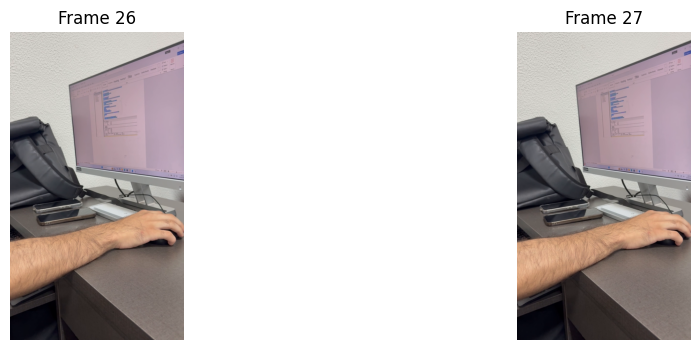

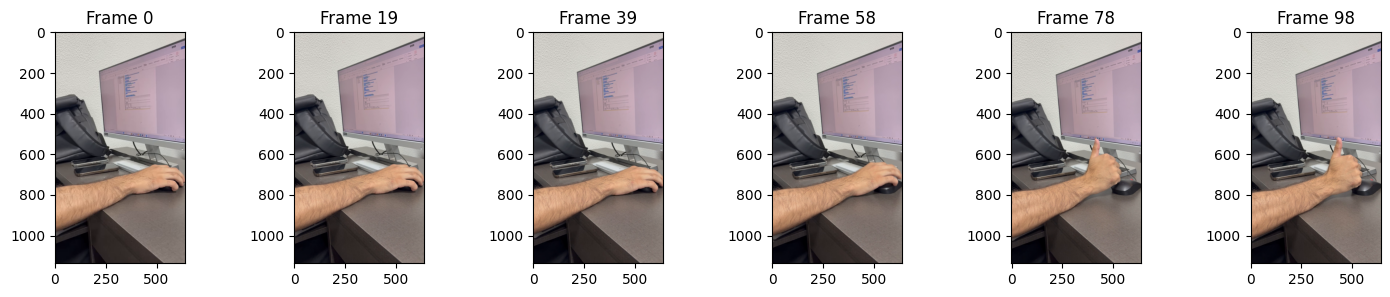

In [13]:
scale = 640 / width
frames = [cv2.resize(f, (640, int(height * scale))) for f in frames]
gray = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY).astype(np.float32) for f in frames]

diffs = [np.abs(gray[i + 1] - gray[i]).mean() for i in range(n - 1)]
k = int(np.argmax(diffs))
f1, f2 = gray[k], gray[k + 1]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(cv2.cvtColor(frames[k], cv2.COLOR_BGR2RGB))
ax[0].set_title(f'Frame {k}')
ax[1].imshow(cv2.cvtColor(frames[k + 1], cv2.COLOR_BGR2RGB))
ax[1].set_title(f'Frame {k + 1}')
for a in ax:
    a.axis('off')
plt.show()

idx = np.linspace(0, n - 1, 6).astype(int)
fig, ax = plt.subplots(1, 6, figsize=(18, 3))
for a, i in zip(ax, idx):
    a.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
    a.set_title(f'Frame {i}')
    a.axis('on')
plt.show()

In [6]:
diff = np.abs(f2 - f1)
mask = (cv2.GaussianBlur(diff, (15, 15), 0) > 15).astype(np.uint8)
ys, xs = np.nonzero(mask)
cy, cx = int(ys.mean()), int(xs.mean())

win, R = 25, 20
H, W = f1.shape
cy = int(np.clip(cy, win + R, H - win - R - 1))
cx = int(np.clip(cx, win + R, W - win - R - 1))
p1 = f1[cy - win:cy + win + 1, cx - win:cx + win + 1]

best_ssd = (np.inf, 0, 0)
best_sad = (np.inf, 0, 0)
for dy in range(-R, R + 1):
    for dx in range(-R, R + 1):
        p2 = f2[cy + dy - win:cy + dy + win + 1, cx + dx - win:cx + dx + win + 1]
        ssd = np.sum((p1 - p2) ** 2)
        sad = np.sum(np.abs(p1 - p2))
        if ssd < best_ssd[0]:
            best_ssd = (ssd, dx, dy)
        if sad < best_sad[0]:
            best_sad = (sad, dx, dy)

print('Window center:', (cx, cy))
print('SSD (dx, dy):', best_ssd[1], best_ssd[2])
print('SAD (dx, dy):', best_sad[1], best_sad[2])

Window center: (364, 628)
SSD (dx, dy): 0 1
SAD (dx, dy): 0 1


In [7]:
g1 = cv2.GaussianBlur(f1, (5, 5), 0)
g2 = cv2.GaussianBlur(f2, (5, 5), 0)
Ix = cv2.Sobel(g1, cv2.CV_32F, 1, 0, ksize=3) / 8
Iy = cv2.Sobel(g1, cv2.CV_32F, 0, 1, ksize=3) / 8
It = g2 - g1

sy = slice(cy - win, cy + win + 1)
sx = slice(cx - win, cx + win + 1)
A = np.stack([Ix[sy, sx].ravel(), Iy[sy, sx].ravel()], axis=1)
b = -It[sy, sx].ravel()
u, v = np.linalg.lstsq(A, b, rcond=None)[0]

print('Least squares (u, v):', round(u, 2), round(v, 2))
print('SSD (dx, dy):', best_ssd[1], best_ssd[2])
print('SAD (dx, dy):', best_sad[1], best_sad[2])

Least squares (u, v): -0.24 1.02
SSD (dx, dy): 0 1
SAD (dx, dy): 0 1


Tracked points: 200
Moving points: 174
Average (u, v): [-0.29717255  1.2045903 ]


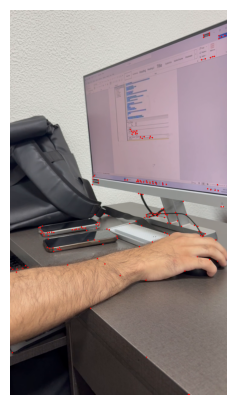

In [8]:
prev8 = f1.astype(np.uint8)
next8 = f2.astype(np.uint8)
person_mask = cv2.dilate(mask, np.ones((15, 15), np.uint8))
pts = cv2.goodFeaturesToTrack(prev8, 200, 0.01, 5, mask=person_mask)
p2, st, err = cv2.calcOpticalFlowPyrLK(prev8, next8, pts, None, winSize=(21, 21), maxLevel=3)

good1 = pts[st == 1]
good2 = p2[st == 1]
lk_flow = good2 - good1
lk_mag = np.linalg.norm(lk_flow, axis=1)
moving = lk_mag > 1

print('Tracked points:', len(good1))
print('Moving points:', moving.sum())
print('Average (u, v):', lk_flow[moving].mean(axis=0))

img = cv2.cvtColor(frames[k], cv2.COLOR_BGR2RGB).copy()
for a, c in zip(good1[moving], good2[moving]):
    cv2.arrowedLine(img, tuple(a.astype(int)), tuple(c.astype(int)), (255, 0, 0), 2)
plt.figure(figsize=(8, 5))
plt.imshow(img)
plt.axis('off')
plt.show()

Mean flow magnitude: 0.9259669
Max flow magnitude: 8.3119545


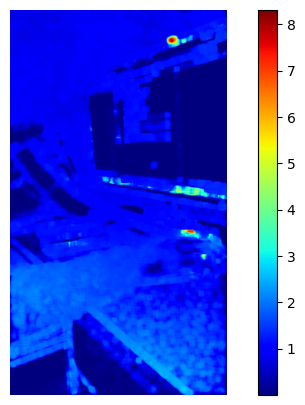

In [12]:
fb = cv2.calcOpticalFlowFarneback(prev8, next8, None, 0.5, 3, 15, 3, 5, 1.2, 0)
fb_mag, _ = cv2.cartToPolar(fb[..., 0], fb[..., 1])

print('Mean flow magnitude:', fb_mag.mean())
print('Max flow magnitude:', fb_mag.max())

plt.figure(figsize=(8, 5))
plt.imshow(fb_mag, cmap='jet')
plt.colorbar()
plt.axis('off')
plt.show()

alpha=1: mean=1.637, max=21.303
alpha=10: mean=0.835, max=5.181
alpha=50: mean=0.271, max=3.293


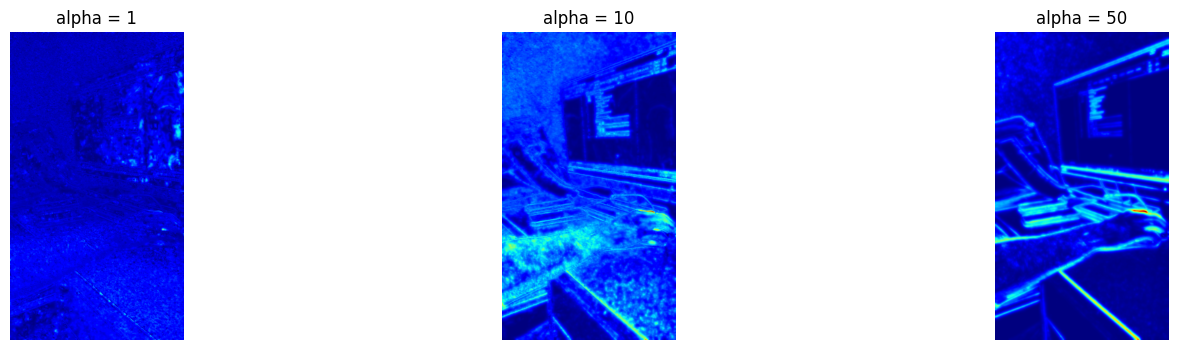

In [10]:
def horn_schunck(I1, I2, alpha, iters=100):
    I1 = cv2.GaussianBlur(I1, (5, 5), 0)
    I2 = cv2.GaussianBlur(I2, (5, 5), 0)
    Ix = (cv2.Sobel(I1, cv2.CV_32F, 1, 0, ksize=3) + cv2.Sobel(I2, cv2.CV_32F, 1, 0, ksize=3)) / 16
    Iy = (cv2.Sobel(I1, cv2.CV_32F, 0, 1, ksize=3) + cv2.Sobel(I2, cv2.CV_32F, 0, 1, ksize=3)) / 16
    It = I2 - I1
    kernel = np.array([[1/12, 1/6, 1/12], [1/6, 0, 1/6], [1/12, 1/6, 1/12]], np.float32)
    u = np.zeros_like(I1)
    v = np.zeros_like(I1)
    for _ in range(iters):
        ub = cv2.filter2D(u, -1, kernel)
        vb = cv2.filter2D(v, -1, kernel)
        d = (Ix * ub + Iy * vb + It) / (alpha ** 2 + Ix ** 2 + Iy ** 2)
        u = ub - Ix * d
        v = vb - Iy * d
    return u, v

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, alpha in zip(ax, [1, 10, 50]):
    u_hs, v_hs = horn_schunck(f1, f2, alpha)
    hs_mag = np.sqrt(u_hs ** 2 + v_hs ** 2)
    print(f'alpha={alpha}: mean={hs_mag.mean():.3f}, max={hs_mag.max():.3f}')
    a.imshow(hs_mag, cmap='jet')
    a.set_title(f'alpha = {alpha}')
    a.axis('off')
plt.show()